In [18]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Make the project root available for imports
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_processing import (
    prepare_temperature_data,
    add_time_gap,
    identify_continuous_blocks,
    summarise_blocks,
    extract_environmental_variables
)

from src.interpolation import (
    create_missing_gap,
    linear_interpolation,
    cubic_spline_interpolation
)

from src.ml_model import (
    train_linear_regression,
    predict_with_regression
)

from src.evaluation import (
    calculate_errors,
    evaluate_missing_gap,
    validate_multiple_blocks,
    summarise_validation,
    evaluate_three_methods,
    validate_three_methods,
    evaluate_cross_variable_reconstruction,
    validate_cross_variable_methods
)

print("Project root:", project_root)
print("Environment ready")

Project root: /Users/ben/Desktop/MMA3001 project/MMA3001-Occupancy-Prediction
Environment ready


In [12]:
env = pd.read_csv("../Data/raw/5EnvSensor_MayToDec2024_180kRows.csv")

env.head()

,id,sensorid,devicetype,jsondata,status,processing_errors,createdate,processdate
0,2,6012002000241,env,"[{""values"": [{""time"": 1702273965, ""value"": 4.1...",Processed,NaN,2024-02-29 03:11:58.210358+11,2024-02-29 03:11:58.210358+11
1,4,6012002000241,env,"[{""values"": [{""time"": 1702273965, ""value"": 4.1...",Processed,NaN,2024-02-29 17:09:08.833822+11,2024-02-29 17:09:08.833822+11
2,5,6012002000326,env,"[{""values"": [{""time"": 1702270857, ""value"": 4.1...",Processed,NaN,2024-02-29 17:09:12.444245+11,2024-02-29 17:09:12.444245+11
3,16,6012002000777,env,"[{""values"": [{""time"": 1683326565, ""value"": 4.1...",Processed,NaN,2024-02-29 17:10:24.443407+11,2024-02-29 17:10:24.443407+11
4,24,6012002000869,env,"[{""values"": [{""time"": 1709186696, ""value"": 4.1...",Processed,NaN,2024-02-29 17:11:11.348578+11,2024-02-29 17:11:11.348578+11


In [13]:
print("Dataset shape:", env.shape)

print("\nColumns:")
print(env.columns)

print("\nData types:")
print(env.dtypes)

Dataset shape: (179447, 8)

Columns:
Index(['id', 'sensorid', 'devicetype', 'jsondata', 'status',
       'processing_errors', 'createdate', 'processdate'],
      dtype='object')

Data types:
id                     int64
sensorid               int64
devicetype            object
jsondata              object
status                object
processing_errors    float64
createdate            object
processdate           object
dtype: object


In [25]:
print(env["jsondata"].iloc[0])

[{"values": [{"time": 1702273965, "value": 4.1875}], "variable": {"id": 66, "name": "Battery", "unit": "V", "source": 0, "structure": 32834}}, {"values": [{"time": 1702273965, "value": 603}], "variable": {"id": 67, "name": "Carbon dioxide", "unit": "ppm", "source": 0, "structure": 32835}}, {"values": [{"time": 1702273965, "value": 66}], "variable": {"id": 72, "name": "Humidity", "unit": "HR%", "source": 0, "structure": 32840}}, {"values": [{"time": 1702273965, "value": 6}], "variable": {"id": 70, "name": "Formaldehyde", "unit": "µg/m3", "source": 0, "structure": 32847}}, {"values": [{"time": 1702273965, "value": 1011}], "variable": {"id": 80, "name": "Pressure", "unit": "mb", "source": 0, "structure": 32848}}, {"values": [{"time": 1702273965, "value": 23.8}], "variable": {"id": 84, "name": "Temperature", "unit": "°C", "source": 0, "structure": 32852}}, {"values": [{"time": 1702273965, "value": 14}], "variable": {"id": 99, "name": "Light Volatile Organic Compounds", "unit": "ppb", "sour

In [24]:
print("Number of sensors:", env["sensorid"].nunique())

print("\nSensor IDs:")
print(env["sensorid"].unique())

Number of sensors: 5

Sensor IDs:
[6012002000241 6012002000326 6012002000777 6012002000869 6012002000227]


In [21]:
sensor_id = 6012002000869

sensor = env[env["sensorid"] == sensor_id].copy()

print(sensor.shape)
sensor.head()

(29341, 8)


,id,sensorid,devicetype,jsondata,status,processing_errors,createdate,processdate
4,24,6012002000869,env,"[{""values"": [{""time"": 1709186696, ""value"": 4.1...",Processed,NaN,2024-02-29 17:11:11.348578+11,2024-02-29 17:11:11.348578+11
8,58,6012002000869,env,"[{""values"": [{""time"": 1709187297, ""value"": 4.1...",Processed,NaN,2024-02-29 17:24:31.400806+11,2024-02-29 17:24:31.400806+11
12,92,6012002000869,env,"[{""values"": [{""time"": 1709188497, ""value"": 4.1...",Processed,NaN,2024-02-29 17:38:05.661335+11,2024-02-29 17:38:05.661335+11
16,126,6012002000869,env,"[{""values"": [{""time"": 1709189097, ""value"": 4.1...",Processed,NaN,2024-02-29 17:51:24.418554+11,2024-02-29 17:51:24.418554+11
20,160,6012002000869,env,"[{""values"": [{""time"": 1709189697, ""value"": 4.1...",Processed,NaN,2024-02-29 18:04:45.909552+11,2024-02-29 18:04:45.909552+11


In [28]:
temperature_data = prepare_temperature_data(
    env,
    sensor_id
)

temperature_data.head()

,time,temperature
0,2024-02-29 06:04:56,24.3
1,2024-02-29 06:14:57,24.0
2,2024-02-29 06:34:57,23.8
3,2024-02-29 06:44:57,23.8
4,2024-02-29 06:54:57,23.8


In [32]:
temp_data = add_time_gap(
    temp_data
)

temp_data = identify_continuous_blocks(
    temp_data,
    expected_minutes=10,
    tolerance_seconds=5
)

block_summary = summarise_blocks(
    temp_data
)

block_summary.head()

,start,end,measurements,duration
block,,,,
157,2024-03-04 16:24:59,2024-03-05 03:14:59,66,0 days 10:50:00
196,2024-03-06 13:04:56,2024-03-06 23:44:56,65,0 days 10:40:00
193,2024-03-06 02:24:59,2024-03-06 11:24:58,55,0 days 08:59:59
1279,2024-05-31 17:15:36,2024-05-31 19:35:36,15,0 days 02:20:00
1277,2024-05-31 12:05:35,2024-05-31 14:25:37,15,0 days 02:20:02


In [39]:
best_block = block_summary.index[0]

ground_truth = (
    temp_data[
        temp_data["block"] == best_block
    ][["time", "temperature"]]
    .reset_index(drop=True)
    .copy()
)

print("Selected block:", best_block)
print("Measurements:", len(ground_truth))

ground_truth.head()

Selected block: 157
Measurements: 66


,time,temperature
0,2024-03-04 16:24:59,22.0
1,2024-03-04 16:34:57,22.0
2,2024-03-04 16:44:58,21.8
3,2024-03-04 16:54:58,21.8
4,2024-03-04 17:04:59,21.8


In [33]:
print("Number of temperature measurements:", len(temp_data))

print("\nMissing values:")
print(temp_data.isnull().sum())

print("\nDuplicate times:")
print(temp_data["time"].duplicated().sum())

print("\nTime range:")
print(temp_data["time"].min())
print(temp_data["time"].max())

Number of temperature measurements: 13800

Missing values:
time           0
temperature    0
time_gap       1
regular_gap    0
new_block      0
block          0
dtype: int64

Duplicate times:
0

Time range:
2024-02-29 06:04:56
2024-06-13 17:45:44


In [35]:
temp_data["time_gap"] = temp_data["time"].diff()

print(temp_data["time_gap"].value_counts().head(10))

time_gap
0 days 00:10:00    9191
0 days 00:10:01    1309
0 days 00:09:59    1256
0 days 00:20:00     899
0 days 00:09:58     305
0 days 00:10:02     286
0 days 00:20:01     194
0 days 00:19:59     173
0 days 00:20:02      58
0 days 00:19:58      49
Name: count, dtype: int64


(803, 6)


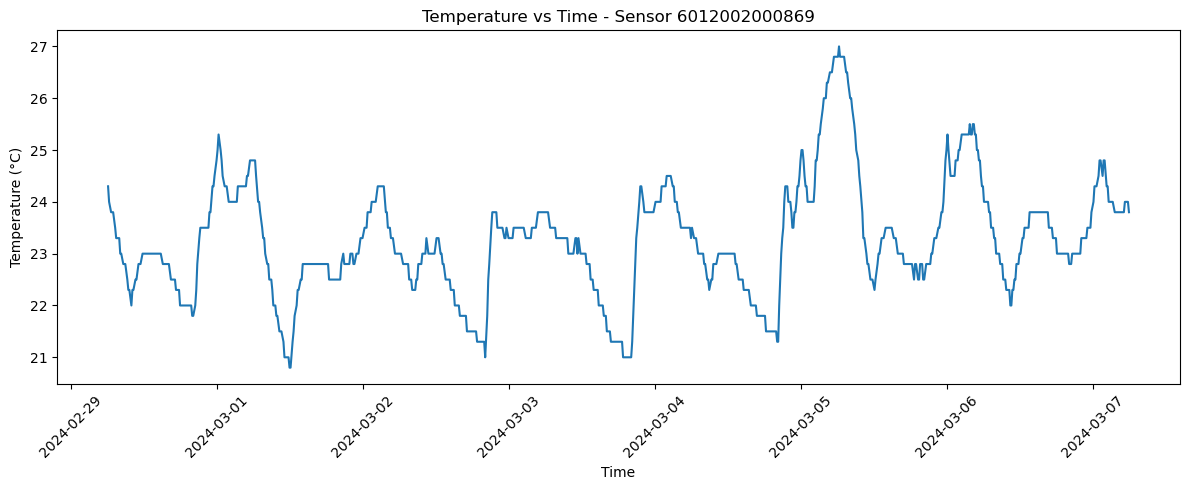

In [36]:
start_time = temp_data["time"].min()
end_time = start_time + pd.Timedelta(days=7)

temp_week = temp_data[
    (temp_data["time"] >= start_time) &
    (temp_data["time"] <= end_time)
].copy()

print(temp_week.shape)
plt.figure(figsize=(12, 5))

plt.plot(
    temp_week["time"],
    temp_week["temperature"]
)

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.title("Temperature vs Time - Sensor 6012002000869")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [41]:
duplicate_count = temp_data["time"].duplicated().sum()

print(
    "Duplicate timestamps after cleaning:",
    duplicate_count
)

Duplicate timestamps after cleaning: 0


In [45]:
print("Raw sensor rows:", len(sensor))
print("Clean temperature rows:", len(temp_data))
print(
    "Duplicate timestamps after cleaning:",
    temp_data["time"].duplicated().sum()
)

print("\nMissing values:")
print(
    temp_data[
        ["time", "temperature"]
    ].isnull().sum()
)

Raw sensor rows: 29341
Clean temperature rows: 13800
Duplicate timestamps after cleaning: 0

Missing values:
time           0
temperature    0
dtype: int64


In [47]:
print(
    temp_data["time_gap"]
    .value_counts()
    .head(10)
)

gap_seconds = (
    temp_data["time_gap"]
    .dt.total_seconds()
)

regular_gap = gap_seconds.between(
    595,
    605
)

print(
    "\nRegular ~10 minute intervals:",
    regular_gap.sum()
)

print(
    "Percentage:",
    round(
        regular_gap.mean() * 100,
        2
    ),
    "%"
)

time_gap
0 days 00:10:00    9191
0 days 00:10:01    1309
0 days 00:09:59    1256
0 days 00:20:00     899
0 days 00:09:58     305
0 days 00:10:02     286
0 days 00:20:01     194
0 days 00:19:59     173
0 days 00:20:02      58
0 days 00:19:58      49
Name: count, dtype: int64

Regular ~10 minute intervals: 12398
Percentage: 89.84 %


Selected block: 157
Number of measurements: 66
Start: 2024-03-04 16:24:59
End: 2024-03-05 03:14:59


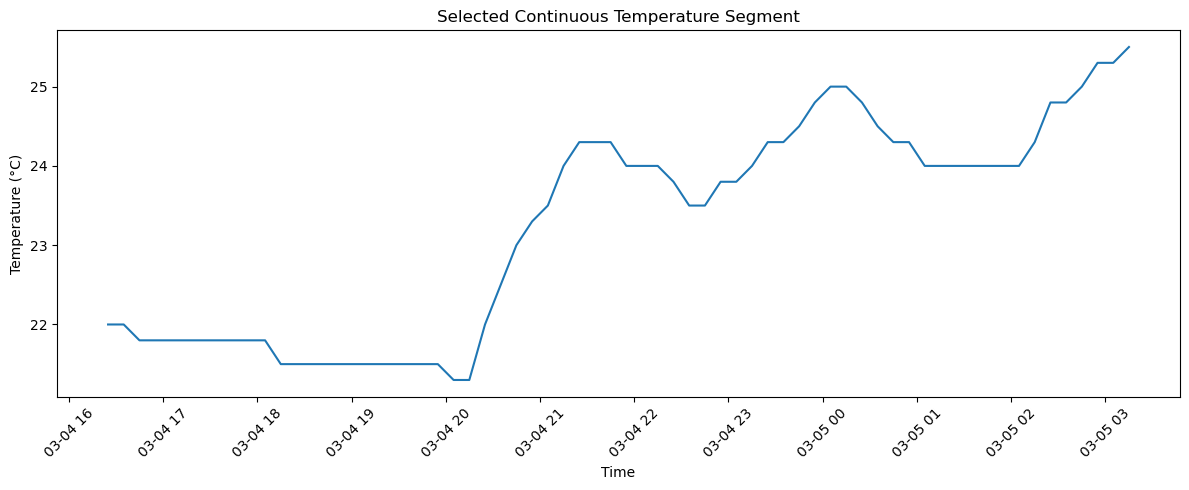

In [49]:
best_block = block_summary.index[0]

ground_truth = (
    temp_data[
        temp_data["block"] == best_block
    ][["time", "temperature"]]
    .reset_index(drop=True)
    .copy()
)

print("Selected block:", best_block)
print("Number of measurements:", len(ground_truth))
print("Start:", ground_truth["time"].min())
print("End:", ground_truth["time"].max())

ground_truth.head()
plt.figure(figsize=(12, 5))

plt.plot(
    ground_truth["time"],
    ground_truth["temperature"]
)

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.title("Selected Continuous Temperature Segment")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [51]:
import numpy as np

In [52]:
# Create the first artificial missing gap
gap_size = 3

start_idx = (
    len(ground_truth) // 2
    - gap_size // 2
)

experiment = create_missing_gap(
    ground_truth[["time", "temperature"]],
    gap_size=gap_size,
    start_idx=start_idx
)

experiment.iloc[
    start_idx - 3:
    start_idx + gap_size + 3
]

,time,temperature,actual
29,2024-03-04 21:14:59,24.0,24.0
30,2024-03-04 21:24:59,24.3,24.3
31,2024-03-04 21:34:58,24.3,24.3
32,2024-03-04 21:44:58,NaN,24.3
33,2024-03-04 21:54:58,NaN,24.0
34,2024-03-04 22:04:59,NaN,24.0
35,2024-03-04 22:14:59,24.0,24.0
36,2024-03-04 22:24:59,23.8,23.8
37,2024-03-04 22:34:59,23.5,23.5


In [57]:
linear_result = linear_interpolation(
    experiment.copy()
)

cubic_result = cubic_spline_interpolation(
    experiment.copy()
)

missing_mask = experiment["temperature"].isna()

comparison = experiment.loc[
    missing_mask,
    ["time", "actual"]
].copy()

comparison["linear"] = linear_result.loc[
    missing_mask,
    "linear"
]

comparison["cubic"] = cubic_result.loc[
    missing_mask,
    "cubic"
]

comparison

,time,actual,linear,cubic
32,2024-03-04 21:44:58,24.3,24.225031,24.248513
33,2024-03-04 21:54:58,24.0,24.150062,24.193456
34,2024-03-04 22:04:59,24.0,24.074969,24.116575


In [61]:
linear_mae, linear_rmse = calculate_errors(
    comparison["actual"],
    comparison["linear"]
)

cubic_mae, cubic_rmse = calculate_errors(
    comparison["actual"],
    comparison["cubic"]
)

results = pd.DataFrame({
    "Method": [
        "Linear",
        "Cubic Spline"
    ],
    "MAE (°C)": [
        linear_mae,
        cubic_mae
    ],
    "RMSE (°C)": [
        linear_rmse,
        cubic_rmse
    ]
})

results

,Method,MAE (°C),RMSE (°C)
0,Linear,0.100000,0.106081
1,Cubic Spline,0.120506,0.133749


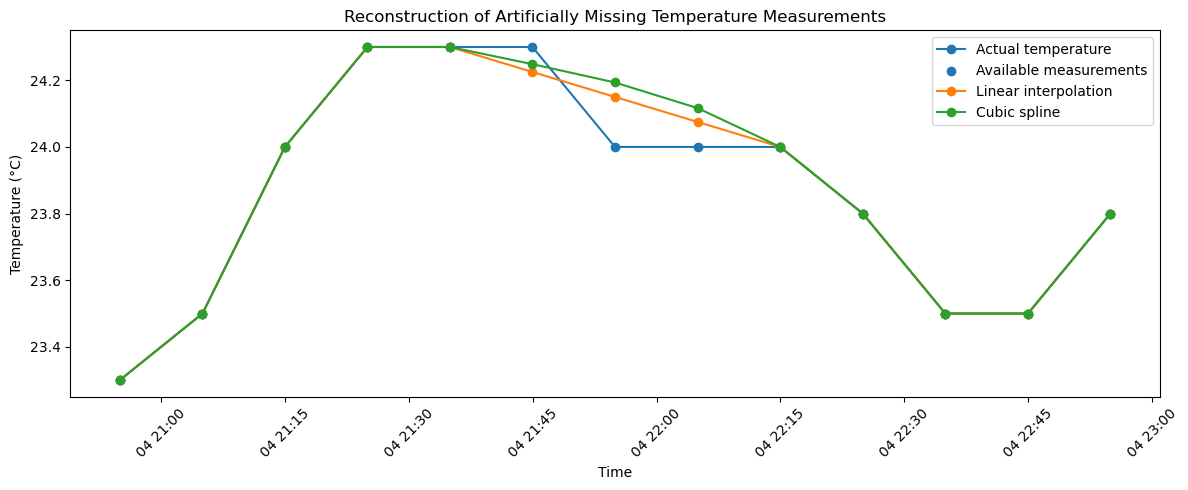

In [62]:
missing_mask = experiment["temperature"].isna()

missing_positions = np.where(
    missing_mask.to_numpy()
)[0]

window_start = max(
    missing_positions[0] - 5,
    0
)

window_end = min(
    missing_positions[-1] + 6,
    len(experiment)
)

plot_data = experiment.copy()

plot_data["linear"] = linear_result["linear"]
plot_data["cubic"] = cubic_result["cubic"]

plot_data = plot_data.iloc[
    window_start:window_end
].copy()

plt.figure(figsize=(12, 5))

plt.plot(
    plot_data["time"],
    plot_data["actual"],
    marker="o",
    label="Actual temperature"
)

plt.scatter(
    plot_data["time"],
    plot_data["temperature"],
    label="Available measurements"
)

plt.plot(
    plot_data["time"],
    plot_data["linear"],
    marker="o",
    label="Lin" \
    "ear interpolation"
)
plt.plot(
    plot_data["time"],
    plot_data["cubic"],
    marker="o",
    label="Cubic spline"
)

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.title("Reconstruction of Artificially Missing Temperature Measurements")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    "../results/figures/reconstruction_example.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [76]:
top_blocks = (
    block_summary
    .head(3)
    .index
    .tolist()
)

gap_sizes = [1, 3, 6, 12]

multi_validation = validate_multiple_blocks(
    temp_data,
    block_ids=top_blocks,
    gap_sizes=gap_sizes,
    positions_per_gap=5
)

print(
    "Selected blocks:",
    top_blocks
)

print(
    "Total experiments:",
    len(multi_validation)
)

multi_validation.head()

Selected blocks: [157, 196, 193]
Total experiments: 60


,gap_size,start_idx,linear_mae,linear_rmse,cubic_mae,cubic_rmse,block
0,1,5,0.00,0.00,0.002643,0.002643,157
1,1,18,0.00,0.00,0.002733,0.002733,157
2,1,32,0.15,0.15,0.159374,0.159374,157
3,1,46,0.10,0.10,0.007228,0.007228,157
4,1,60,0.25,0.25,0.205517,0.205517,157


In [79]:
multi_summary = summarise_validation(
    multi_validation
)

multi_summary

,n_tests,linear_mae_mean,linear_mae_std,linear_rmse_mean,linear_rmse_std,cubic_mae_mean,cubic_mae_std,cubic_rmse_mean,cubic_rmse_std
gap_size,,,,,,,,,
1,15,0.076667,0.075277,0.076667,0.075277,0.078649,0.074921,0.078649,0.074921
3,15,0.076677,0.065108,0.084705,0.074358,0.108640,0.069849,0.119482,0.076219
6,15,0.137453,0.071917,0.156580,0.077941,0.192005,0.137700,0.218580,0.142200
12,15,0.237131,0.216897,0.277215,0.246427,0.218769,0.214474,0.253208,0.224939


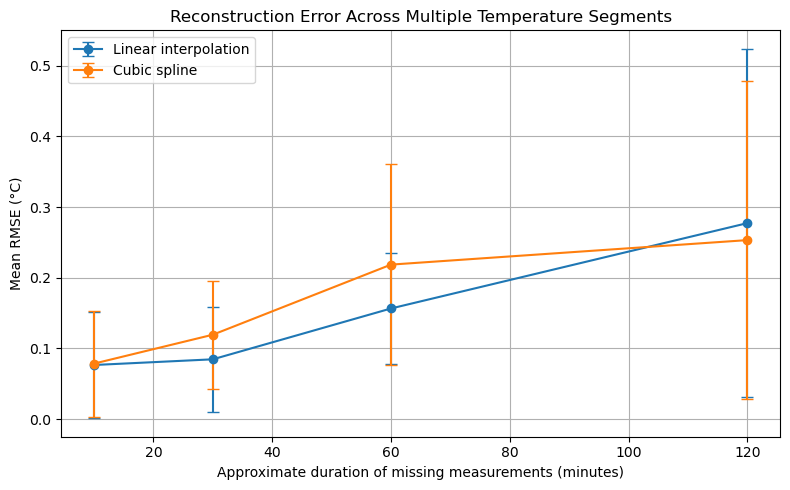

In [80]:
plot_multi = multi_summary.reset_index().copy()

plot_multi["missing_minutes"] = (
    plot_multi["gap_size"] * 10
)

plt.figure(figsize=(8, 5))

plt.errorbar(
    plot_multi["missing_minutes"],
    plot_multi["linear_rmse_mean"],
    yerr=plot_multi["linear_rmse_std"],
    marker="o",
    capsize=4,
    label="Linear interpolation"
)

plt.errorbar(
    plot_multi["missing_minutes"],
    plot_multi["cubic_rmse_mean"],
    yerr=plot_multi["cubic_rmse_std"],
    marker="o",
    capsize=4,
    label="Cubic spline"
)

plt.xlabel(
    "Approximate duration of missing measurements (minutes)"
)

plt.ylabel("Mean RMSE (°C)")

plt.title(
    "Reconstruction Error Across Multiple Temperature Segments"
)

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "../results/figures/rmse_vs_missing_duration.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [82]:
final_results = multi_summary.reset_index().copy()

final_results["missing_minutes"] = (
    final_results["gap_size"] * 10
)

final_results = final_results[
    [
        "gap_size",
        "missing_minutes",
        "n_tests",
        "linear_mae_mean",
        "linear_rmse_mean",
        "cubic_mae_mean",
        "cubic_rmse_mean"
    ]
]

final_results.round(4)

,gap_size,missing_minutes,n_tests,linear_mae_mean,linear_rmse_mean,cubic_mae_mean,cubic_rmse_mean
0,1,10,15,0.0767,0.0767,0.0786,0.0786
1,3,30,15,0.0767,0.0847,0.1086,0.1195
2,6,60,15,0.1375,0.1566,0.1920,0.2186
3,12,120,15,0.2371,0.2772,0.2188,0.2532


In [85]:
tables_dir = project_root / "results" / "tables"
figures_dir = project_root / "results" / "figures"

tables_dir.mkdir(
    parents=True,
    exist_ok=True
)

figures_dir.mkdir(
    parents=True,
    exist_ok=True
)

final_results.to_csv(
    tables_dir / "interpolation_validation_results.csv",
    index=False
)

print("Results saved successfully")

Results saved successfully


In [86]:
import sys
from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_processing import (
    prepare_temperature_data,
    add_time_gap,
    identify_continuous_blocks,
    summarise_blocks
)


In [94]:
sensor_id = 6012002000869

clean_test = prepare_temperature_data(
    env,
    sensor_id
)

clean_test = add_time_gap(clean_test)

clean_test = identify_continuous_blocks(
    clean_test,
    expected_minutes=10,
    tolerance_seconds=5
)

block_test = summarise_blocks(clean_test)

print("Clean measurements:", len(clean_test))
block_test.head()

Clean measurements: 13800


,start,end,measurements,duration
block,,,,
157,2024-03-04 16:24:59,2024-03-05 03:14:59,66,0 days 10:50:00
196,2024-03-06 13:04:56,2024-03-06 23:44:56,65,0 days 10:40:00
193,2024-03-06 02:24:59,2024-03-06 11:24:58,55,0 days 08:59:59
1279,2024-05-31 17:15:36,2024-05-31 19:35:36,15,0 days 02:20:00
1277,2024-05-31 12:05:35,2024-05-31 14:25:37,15,0 days 02:20:02


In [95]:
from src.interpolation import (
    create_missing_gap,
    linear_interpolation,
    cubic_spline_interpolation
)

print("interpolation imported successfully")

interpolation imported successfully


In [96]:
ground_truth_test = (
    clean_test[clean_test["block"] == 157]
    [["time", "temperature"]]
    .reset_index(drop=True)
    .copy()
)

experiment_test = create_missing_gap(
    ground_truth_test,
    gap_size=3,
    start_idx=32
)

experiment_test = linear_interpolation(
    experiment_test
)

experiment_test = cubic_spline_interpolation(
    experiment_test
)

experiment_test.loc[
    32:34,
    ["time", "actual", "temperature", "linear", "cubic"]
]

,time,actual,temperature,linear,cubic
32,2024-03-04 21:44:58,24.3,NaN,24.225031,24.248513
33,2024-03-04 21:54:58,24.0,NaN,24.150062,24.193456
34,2024-03-04 22:04:59,24.0,NaN,24.074969,24.116575


## Multivariable Sensor Analysis

Pressure and humidity are investigated as additional environmental variables
that may contain useful information for reconstructing missing temperature
measurements.

In [104]:
multi_data = sensor["jsondata"].apply(
    extract_environmental_variables
)

multi_data.head()

,timestamp,temperature,humidity,pressure
4,1.709187e+09,24.3,56.0,1010.0
8,1.709187e+09,24.0,56.0,1010.0
12,1.709188e+09,23.8,56.0,1010.0
16,1.709189e+09,23.8,56.0,1010.0
20,1.709190e+09,23.8,57.0,1010.0


In [105]:
multi_data["time"] = pd.to_datetime(
    multi_data["timestamp"],
    unit="s"
)

for col in ["temperature", "humidity", "pressure"]:
    multi_data[col] = pd.to_numeric(
        multi_data[col],
        errors="coerce"
    )

multi_data = multi_data[
    ["time", "temperature", "humidity", "pressure"]
].copy()

multi_data.head()

,time,temperature,humidity,pressure
4,2024-02-29 06:04:56,24.3,56.0,1010.0
8,2024-02-29 06:14:57,24.0,56.0,1010.0
12,2024-02-29 06:34:57,23.8,56.0,1010.0
16,2024-02-29 06:44:57,23.8,56.0,1010.0
20,2024-02-29 06:54:57,23.8,57.0,1010.0


In [106]:
print("Original rows:", len(multi_data))

print("\nMissing values:")
print(multi_data.isnull().sum())

Original rows: 29341

Missing values:
time           0
temperature    0
humidity       0
pressure       0
dtype: int64


In [108]:
duplicate_check = (
    multi_data
    .groupby("time")
    [["temperature", "humidity", "pressure"]]
    .nunique()
)

conflicts = duplicate_check[
    (duplicate_check["temperature"] > 1) |
    (duplicate_check["humidity"] > 1) |
    (duplicate_check["pressure"] > 1)
]

print(
    "Conflicting duplicate timestamps:",
    len(conflicts)
)

Conflicting duplicate timestamps: 0


In [109]:
multi_clean = (
    multi_data
    .drop_duplicates(
        subset="time",
        keep="first"
    )
    .dropna(
        subset=[
            "temperature",
            "humidity",
            "pressure"
        ]
    )
    .sort_values("time")
    .reset_index(drop=True)
)

print("Clean rows:", len(multi_clean))

multi_clean.head()

Clean rows: 13800


,time,temperature,humidity,pressure
0,2024-02-29 06:04:56,24.3,56.0,1010.0
1,2024-02-29 06:14:57,24.0,56.0,1010.0
2,2024-02-29 06:34:57,23.8,56.0,1010.0
3,2024-02-29 06:44:57,23.8,56.0,1010.0
4,2024-02-29 06:54:57,23.8,57.0,1010.0


## Case 1: Relationship Between Environmental Variables

Before using pressure and humidity to reconstruct missing temperature
measurements, the relationships between the three environmental variables
are investigated.

The analysis considers:

- Temperature vs Humidity
- Temperature vs Pressure
- Humidity vs Pressure

In [110]:
correlation = multi_clean[
    ["temperature", "humidity", "pressure"]
].corr()

correlation

,temperature,humidity,pressure
temperature,1.000000,-0.123493,-0.103849
humidity,-0.123493,1.000000,-0.347976
pressure,-0.103849,-0.347976,1.000000


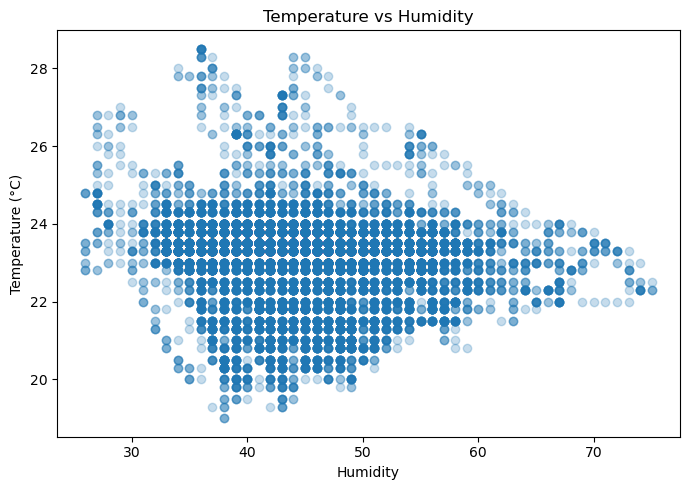

In [111]:
plt.figure(figsize=(7, 5))

plt.scatter(
    multi_clean["humidity"],
    multi_clean["temperature"],
    alpha=0.25
)

plt.xlabel("Humidity")
plt.ylabel("Temperature (°C)")
plt.title("Temperature vs Humidity")

plt.tight_layout()
plt.show()

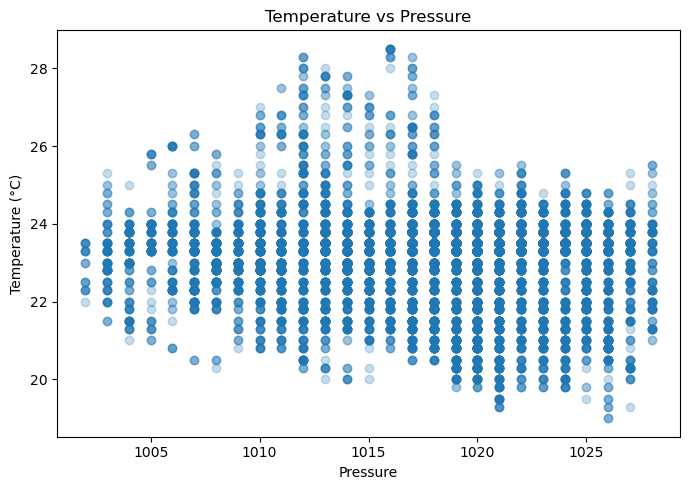

In [41]:
plt.figure(figsize=(7, 5))

plt.scatter(
    multi_clean["pressure"],
    multi_clean["temperature"],
    alpha=0.25
)

plt.xlabel("Pressure")
plt.ylabel("Temperature (°C)")
plt.title("Temperature vs Pressure")

plt.tight_layout()
plt.show()

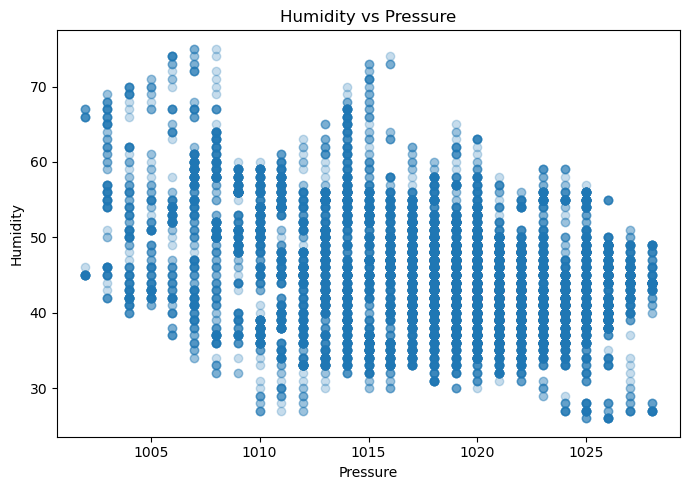

In [112]:
plt.figure(figsize=(7, 5))

plt.scatter(
    multi_clean["pressure"],
    multi_clean["humidity"],
    alpha=0.25
)

plt.xlabel("Pressure")
plt.ylabel("Humidity")
plt.title("Humidity vs Pressure")

plt.tight_layout()
plt.show()

## Case 2: Temperature Prediction Using Multiple Linear Regression

Multiple linear regression is used to investigate whether humidity and
pressure can be combined to predict temperature.

The model uses humidity and pressure as input variables and temperature
as the target variable.

In [119]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [120]:
split_index = int(len(multi_clean) * 0.8)

train_data = multi_clean.iloc[:split_index].copy()
test_data = multi_clean.iloc[split_index:].copy()

print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))

Training rows: 11040
Testing rows: 2760


In [121]:
mlr_model = train_linear_regression(
    train_data,
    predictors=["humidity", "pressure"],
    target="temperature"
)

y_test = test_data["temperature"]

y_pred = predict_with_regression(
    mlr_model,
    test_data,
    predictors=["humidity", "pressure"]
)

In [122]:
mae, rmse = calculate_errors(
    y_test,
    y_pred
)

r2 = r2_score(
    y_test,
    y_pred
)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 0.925719043887707
RMSE: 1.2692440526189261
R²: -0.40688344783544284


In [123]:
print(
    "Humidity coefficient:",
    mlr_model.coef_[0]
)

print(
    "Pressure coefficient:",
    mlr_model.coef_[1]
)

print(
    "Intercept:",
    mlr_model.intercept_
)

Humidity coefficient: -0.046617628400769405
Pressure coefficient: -0.06135664776925872
Intercept: 87.77387484904084


In [124]:
print(
    "Training period:",
    train_data["time"].min(),
    "to",
    train_data["time"].max()
)

print(
    "Testing period:",
    test_data["time"].min(),
    "to",
    test_data["time"].max()
)

print("\nMean temperature:")
print("Train:", train_data["temperature"].mean())
print("Test:", test_data["temperature"].mean())

print("\nMean prediction:")
print(y_pred.mean())

Training period: 2024-02-29 06:04:56 to 2024-05-24 06:05:37
Testing period: 2024-05-24 06:15:37 to 2024-06-13 17:45:44

Mean temperature:
Train: 23.127192028985508
Test: 22.93880434782609

Mean prediction:
23.611857285147003


In [125]:
multi_blocks = add_time_gap(multi_clean)

multi_blocks = identify_continuous_blocks(
    multi_blocks,
    expected_minutes=10,
    tolerance_seconds=5
)

multi_block_summary = summarise_blocks(multi_blocks)

multi_block_summary.head(10)

,start,end,measurements,duration
block,,,,
157,2024-03-04 16:24:59,2024-03-05 03:14:59,66,0 days 10:50:00
196,2024-03-06 13:04:56,2024-03-06 23:44:56,65,0 days 10:40:00
193,2024-03-06 02:24:59,2024-03-06 11:24:58,55,0 days 08:59:59
1279,2024-05-31 17:15:36,2024-05-31 19:35:36,15,0 days 02:20:00
1277,2024-05-31 12:05:35,2024-05-31 14:25:37,15,0 days 02:20:02
1274,2024-05-31 04:25:35,2024-05-31 06:45:35,15,0 days 02:20:00
1195,2024-05-22 14:45:34,2024-05-22 17:05:33,15,0 days 02:19:59
1272,2024-05-30 23:15:35,2024-05-31 01:35:35,15,0 days 02:20:00
1197,2024-05-22 19:55:33,2024-05-22 22:15:34,15,0 days 02:20:01


In [126]:
top_ml_blocks = multi_block_summary.head(3).index.tolist()

print("Selected blocks:", top_ml_blocks)

multi_block_summary.loc[top_ml_blocks]

Selected blocks: [157, 196, 193]


,start,end,measurements,duration
block,,,,
157,2024-03-04 16:24:59,2024-03-05 03:14:59,66,0 days 10:50:00
196,2024-03-06 13:04:56,2024-03-06 23:44:56,65,0 days 10:40:00
193,2024-03-06 02:24:59,2024-03-06 11:24:58,55,0 days 08:59:59


In [127]:
example_block = top_ml_blocks[0]

example_three_methods = evaluate_three_methods(
    multi_blocks,
    block_id=example_block,
    gap_size=3,
    start_idx=20
)

example_three_methods

{'block': 157,
 'gap_size': 3,
 'linear_mae': 0.06658336804109292,
 'linear_rmse': 0.0706223347716652,
 'cubic_mae': 0.30862883343747666,
 'cubic_rmse': 0.3244125028366708,
 'regression_mae': 1.7221855770271723,
 'regression_rmse': 1.7240870436479752}

In [128]:
gap_sizes = [1, 3, 6, 12]

three_method_results = validate_three_methods(
    multi_blocks,
    block_ids=top_ml_blocks,
    gap_sizes=gap_sizes,
    positions_per_gap=5
)

print("Total experiments:", len(three_method_results))

three_method_results.head()

Total experiments: 60


,block,gap_size,linear_mae,linear_rmse,cubic_mae,cubic_rmse,regression_mae,regression_rmse,start_idx
0,157,1,0.00,0.00,0.002643,0.002643,1.427452,1.427452,5
1,157,1,0.00,0.00,0.002733,0.002733,1.664945,1.664945,18
2,157,1,0.15,0.15,0.159374,0.159374,1.112727,1.112727,32
3,157,1,0.10,0.10,0.007228,0.007228,1.778499,1.778499,46
4,157,1,0.25,0.25,0.205517,0.205517,1.204931,1.204931,60


In [129]:
three_method_summary = (
    three_method_results
    .groupby("gap_size")
    .agg(
        n_tests=("block", "count"),

        linear_mae_mean=("linear_mae", "mean"),
        linear_mae_std=("linear_mae", "std"),
        linear_rmse_mean=("linear_rmse", "mean"),
        linear_rmse_std=("linear_rmse", "std"),

        cubic_mae_mean=("cubic_mae", "mean"),
        cubic_mae_std=("cubic_mae", "std"),
        cubic_rmse_mean=("cubic_rmse", "mean"),
        cubic_rmse_std=("cubic_rmse", "std"),

        regression_mae_mean=("regression_mae", "mean"),
        regression_mae_std=("regression_mae", "std"),
        regression_rmse_mean=("regression_rmse", "mean"),
        regression_rmse_std=("regression_rmse", "std")
    )
    .reset_index()
)

three_method_summary

,gap_size,n_tests,linear_mae_mean,linear_mae_std,linear_rmse_mean,linear_rmse_std,cubic_mae_mean,cubic_mae_std,cubic_rmse_mean,cubic_rmse_std,regression_mae_mean,regression_mae_std,regression_rmse_mean,regression_rmse_std
0,1,15,0.076667,0.075277,0.076667,0.075277,0.078649,0.074921,0.078649,0.074921,1.024837,0.629595,1.024837,0.629595
1,3,15,0.076677,0.065108,0.084705,0.074358,0.108640,0.069849,0.119482,0.076219,0.977655,0.607751,0.985870,0.603641
2,6,15,0.137453,0.071917,0.156580,0.077941,0.192005,0.137700,0.218580,0.142200,0.953058,0.612858,0.966097,0.607599
3,12,15,0.237131,0.216897,0.277215,0.246427,0.218769,0.214474,0.253208,0.224939,0.874063,0.555977,0.916001,0.557193


In [130]:
comparison_summary = three_method_summary[
    [
        "gap_size",
        "n_tests",
        "linear_rmse_mean",
        "cubic_rmse_mean",
        "regression_rmse_mean"
    ]
]

comparison_summary

,gap_size,n_tests,linear_rmse_mean,cubic_rmse_mean,regression_rmse_mean
0,1,15,0.076667,0.078649,1.024837
1,3,15,0.084705,0.119482,0.985870
2,6,15,0.156580,0.218580,0.966097
3,12,15,0.277215,0.253208,0.916001


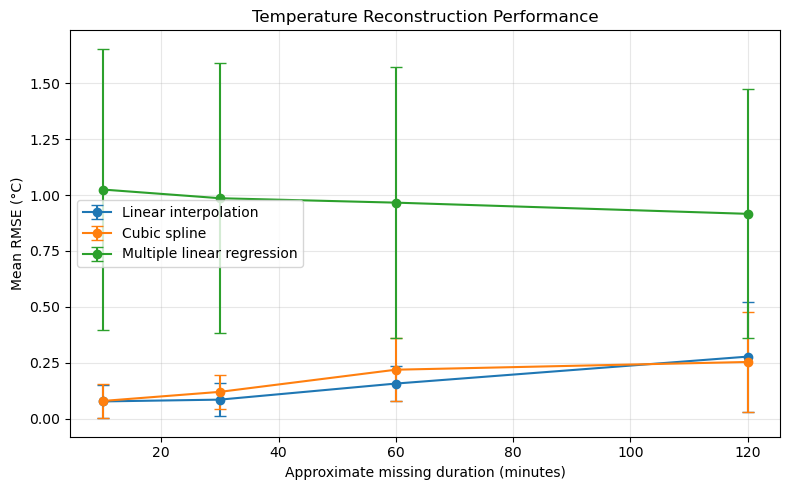

In [131]:
plot_three = three_method_summary.copy()

plot_three["missing_minutes"] = (
    plot_three["gap_size"] * 10
)

plt.figure(figsize=(8, 5))

plt.errorbar(
    plot_three["missing_minutes"],
    plot_three["linear_rmse_mean"],
    yerr=plot_three["linear_rmse_std"],
    marker="o",
    capsize=4,
    label="Linear interpolation"
)

plt.errorbar(
    plot_three["missing_minutes"],
    plot_three["cubic_rmse_mean"],
    yerr=plot_three["cubic_rmse_std"],
    marker="o",
    capsize=4,
    label="Cubic spline"
)

plt.errorbar(
    plot_three["missing_minutes"],
    plot_three["regression_rmse_mean"],
    yerr=plot_three["regression_rmse_std"],
    marker="o",
    capsize=4,
    label="Multiple linear regression"
)

plt.xlabel("Approximate missing duration (minutes)")
plt.ylabel("Mean RMSE (°C)")
plt.title("Temperature Reconstruction Performance")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../results/figures/three_method_rmse_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [141]:
three_method_summary.to_csv(
    "../results/tables/three_method_validation_summary.csv",
    index=False

  
)

## Case 1: Reconstruction Between Pressure and Humidity

This case investigates whether pressure and humidity contain enough
information to reconstruct each other when one sensor variable is missing.

Two scenarios are tested:

1. Missing humidity reconstructed using pressure.
2. Missing pressure reconstructed using humidity.

Artificial gaps are introduced so that the original measurements remain
available as ground truth for validation.

In [132]:
humidity_example = evaluate_cross_variable_reconstruction(
    multi_blocks,
    block_id=157,
    target="humidity",
    predictor="pressure",
    gap_size=3,
    start_idx=20
)

humidity_example

{'block': 157,
 'target': 'humidity',
 'predictor': 'pressure',
 'gap_size': 3,
 'start_idx': 20,
 'interpolation_mae': 0.3329168402054705,
 'interpolation_rmse': 0.3531116738583302,
 'regression_mae': 0.5405711450954035,
 'regression_rmse': 0.7172442994768087}

In [133]:
pressure_example = evaluate_cross_variable_reconstruction(
    multi_blocks,
    block_id=157,
    target="pressure",
    predictor="humidity",
    gap_size=3,
    start_idx=20
)

pressure_example

{'block': 157,
 'target': 'pressure',
 'predictor': 'humidity',
 'gap_size': 3,
 'start_idx': 20,
 'interpolation_mae': 0.0,
 'interpolation_rmse': 0.0,
 'regression_mae': 3.2321623327106863,
 'regression_rmse': 3.2346181619161345}

Even error for interpolation is better here, it doesn't mean this method is 100% correct, which just represents in this location interpolation performs better

In [134]:
cross_variable_results = validate_cross_variable_methods(
    multi_blocks,
    block_ids=top_ml_blocks,
    gap_sizes=[1, 3, 6, 12],
    positions_per_gap=5
)

print(
    "Total experiments:",
    len(cross_variable_results)
)

cross_variable_results.head()

Total experiments: 120


,block,target,predictor,gap_size,start_idx,interpolation_mae,interpolation_rmse,regression_mae,regression_rmse
0,157,humidity,pressure,1,5,0.0,0.0,1.249176,1.249176
1,157,humidity,pressure,1,18,0.0,0.0,0.207238,0.207238
2,157,humidity,pressure,1,32,0.0,0.0,1.336348,1.336348
3,157,humidity,pressure,1,46,0.5,0.5,1.792762,1.792762
4,157,humidity,pressure,1,60,0.5,0.5,14.249176,14.249176


In [136]:
cross_variable_summary = (
    cross_variable_results
    .groupby(["target", "predictor", "gap_size"])
    .agg(
        n_tests=("block", "count"),

        interpolation_mae_mean=(
            "interpolation_mae",
            "mean"
        ),

        interpolation_mae_std=(
            "interpolation_mae",
            "std"
        ),

        interpolation_rmse_mean=(
            "interpolation_rmse",
            "mean"
        ),

        interpolation_rmse_std=(
            "interpolation_rmse",
            "std"
        ),

        regression_mae_mean=(
            "regression_mae",
            "mean"
        ),

        regression_mae_std=(
            "regression_mae",
            "std"
        ),

        regression_rmse_mean=(
            "regression_rmse",
            "mean"
        ),

        regression_rmse_std=(
            "regression_rmse",
            "std"
        )
    )
    .reset_index()
)

cross_variable_summary

,target,predictor,gap_size,n_tests,interpolation_mae_mean,interpolation_mae_std,interpolation_rmse_mean,interpolation_rmse_std,regression_mae_mean,regression_mae_std,regression_rmse_mean,regression_rmse_std
0,humidity,pressure,1,15,0.233472,0.258122,0.233472,0.258122,7.241782,5.719097,7.241782,5.719097
1,humidity,pressure,3,15,0.388824,0.411336,0.420627,0.430391,6.920549,5.620778,6.988535,5.585903
2,humidity,pressure,6,15,0.596776,0.469499,0.674842,0.503412,6.700210,5.584388,6.837396,5.528826
3,humidity,pressure,12,15,0.885321,0.750618,1.038229,0.865053,6.405994,5.292727,6.670867,5.222743
4,pressure,humidity,1,15,0.100028,0.207077,0.100028,0.207077,3.760151,1.749092,3.760151,1.749092
5,pressure,humidity,3,15,0.155569,0.231184,0.167593,0.249340,3.666657,1.620198,3.674075,1.620746
6,pressure,humidity,6,15,0.214294,0.263302,0.240761,0.293001,3.629581,1.418662,3.659085,1.394875
7,pressure,humidity,12,15,0.245723,0.187785,0.296330,0.231967,3.545481,1.206313,3.613086,1.173755


In [137]:
case1_comparison = cross_variable_summary[
    [
        "target",
        "predictor",
        "gap_size",
        "n_tests",
        "interpolation_rmse_mean",
        "regression_rmse_mean"
    ]
]

case1_comparison

,target,predictor,gap_size,n_tests,interpolation_rmse_mean,regression_rmse_mean
0,humidity,pressure,1,15,0.233472,7.241782
1,humidity,pressure,3,15,0.420627,6.988535
2,humidity,pressure,6,15,0.674842,6.837396
3,humidity,pressure,12,15,1.038229,6.670867
4,pressure,humidity,1,15,0.100028,3.760151
5,pressure,humidity,3,15,0.167593,3.674075
6,pressure,humidity,6,15,0.240761,3.659085
7,pressure,humidity,12,15,0.296330,3.613086


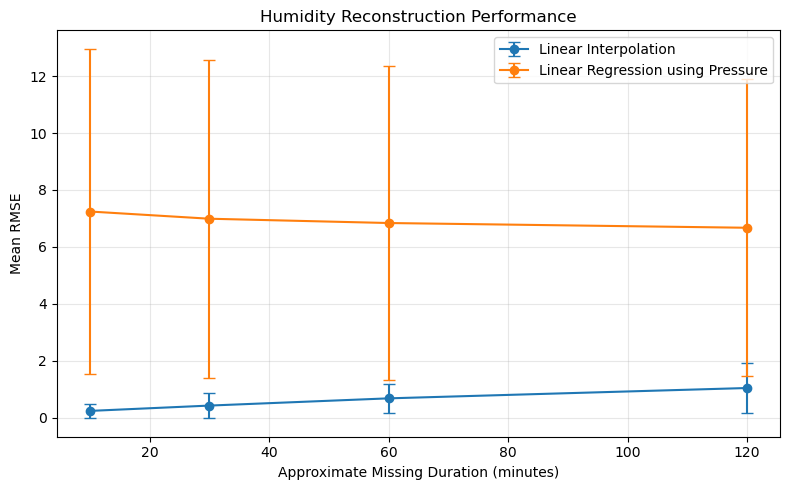

In [138]:
humidity_summary = cross_variable_summary[
    cross_variable_summary["target"] == "humidity"
].copy()

duration_minutes = [10, 30, 60, 120]

plt.figure(figsize=(8, 5))

plt.errorbar(
    duration_minutes,
    humidity_summary["interpolation_rmse_mean"],
    yerr=humidity_summary["interpolation_rmse_std"],
    marker="o",
    capsize=4,
    label="Linear Interpolation"
)

plt.errorbar(
    duration_minutes,
    humidity_summary["regression_rmse_mean"],
    yerr=humidity_summary["regression_rmse_std"],
    marker="o",
    capsize=4,
    label="Linear Regression using Pressure"
)

plt.xlabel("Approximate Missing Duration (minutes)")
plt.ylabel("Mean RMSE")
plt.title("Humidity Reconstruction Performance")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../results/figures/humidity_reconstruction_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

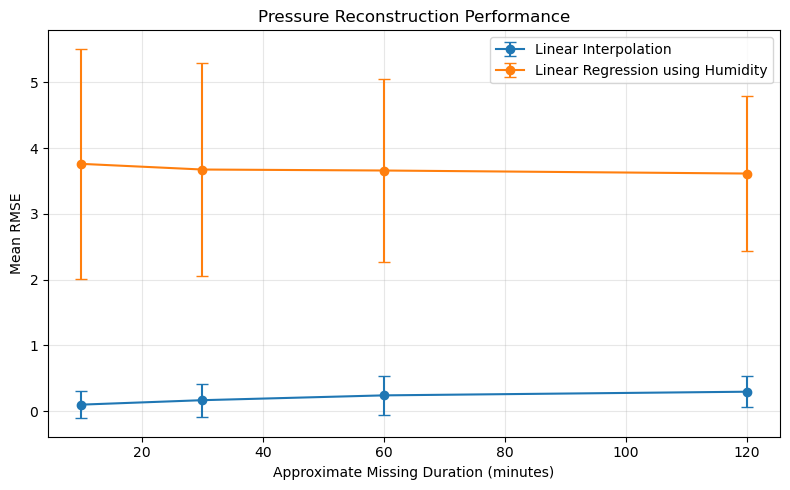

In [139]:
pressure_summary = cross_variable_summary[
    cross_variable_summary["target"] == "pressure"
].copy()

plt.figure(figsize=(8, 5))

plt.errorbar(
    duration_minutes,
    pressure_summary["interpolation_rmse_mean"],
    yerr=pressure_summary["interpolation_rmse_std"],
    marker="o",
    capsize=4,
    label="Linear Interpolation"
)

plt.errorbar(
    duration_minutes,
    pressure_summary["regression_rmse_mean"],
    yerr=pressure_summary["regression_rmse_std"],
    marker="o",
    capsize=4,
    label="Linear Regression using Humidity"
)

plt.xlabel("Approximate Missing Duration (minutes)")
plt.ylabel("Mean RMSE")
plt.title("Pressure Reconstruction Performance")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../results/figures/pressure_reconstruction_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [140]:
cross_variable_results.to_csv(
    "../results/tables/case1_cross_variable_results.csv",
    index=False
)

cross_variable_summary.to_csv(
    "../results/tables/case1_cross_variable_summary.csv",
    index=False
)

In [142]:
from pathlib import Path

Path("../results/tables").mkdir(
    parents=True,
    exist_ok=True
)

three_method_summary.to_csv(
    "../results/tables/three_method_validation_summary.csv",
    index=False
)

print("Three-method summary saved successfully.")

Three-method summary saved successfully.


### Comparison of Reconstruction Methods

The three reconstruction methods show substantially different performance.

Linear interpolation and cubic spline interpolation produced much lower RMSE values than multiple linear regression across all tested missing-data durations. Linear interpolation performed slightly better for short and medium gaps, particularly around 30 and 60 minutes, while cubic spline interpolation produced a slightly lower mean RMSE for the longest 120-minute gaps.

The multiple linear regression model produced considerably larger errors. This is consistent with the relatively weak relationships observed between temperature, humidity and pressure. The regression model therefore does not provide enough information to accurately reconstruct missing temperature measurements using these two environmental variables alone.

Overall, the results suggest that time-based interpolation is more suitable for this dataset than the tested regression approach. Reconstruction accuracy also generally decreases as the duration of missing measurements increases.